In [1]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

from pathlib import Path

In [2]:
def display_images(images, columns=2, figsize=(8, 10)):
    rows = (len(images) + columns - 1) // columns
    plt.figure(figsize=figsize)

    for i, (title, image) in enumerate(images.items(), start=1):
        plt.subplot(rows, columns, i)
        plt.imshow(image, cmap="gray")
        plt.title(title)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

### Input image and binary mask

Change `imagePath` to use another image. Relative paths are checked from the current folder, then its parent; absolute paths also work. The image is loaded in grayscale, and Otsu thresholding creates a 0/1 mask for binary operations. All image arrays use the loaded image dimensions.

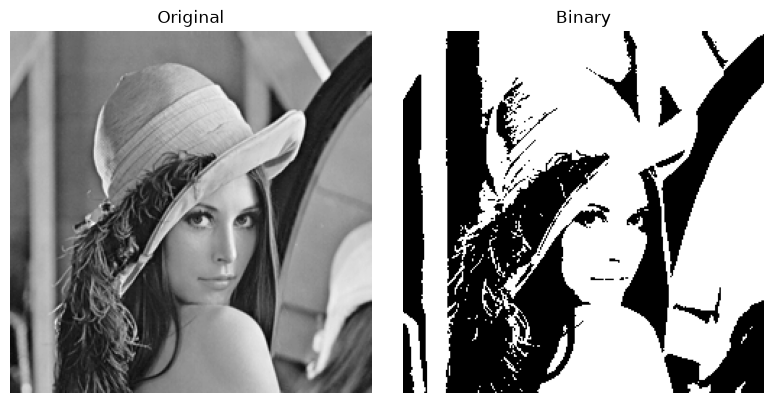

In [3]:
imagePath = Path("../images/lenna.png")

gray = cv.imread(str(imagePath), cv.IMREAD_GRAYSCALE)

threshold, binary = cv.threshold(gray, 0, 1, cv.THRESH_BINARY + cv.THRESH_OTSU)

display_images({"Original": gray, "Binary": binary}, columns=2, figsize=(8, 4))

### Noise settings

A fixed random seed makes the results repeatable. `noiseAmount` is the fraction of pixels replaced by salt or pepper. Gaussian noise has mean 0 and standard deviation `gaussianSigma`; uniform noise is sampled between `-uniformLimit` and `uniformLimit`. Additive noise is calculated in floating point, then clipped to 0-255 before conversion to `uint8`.

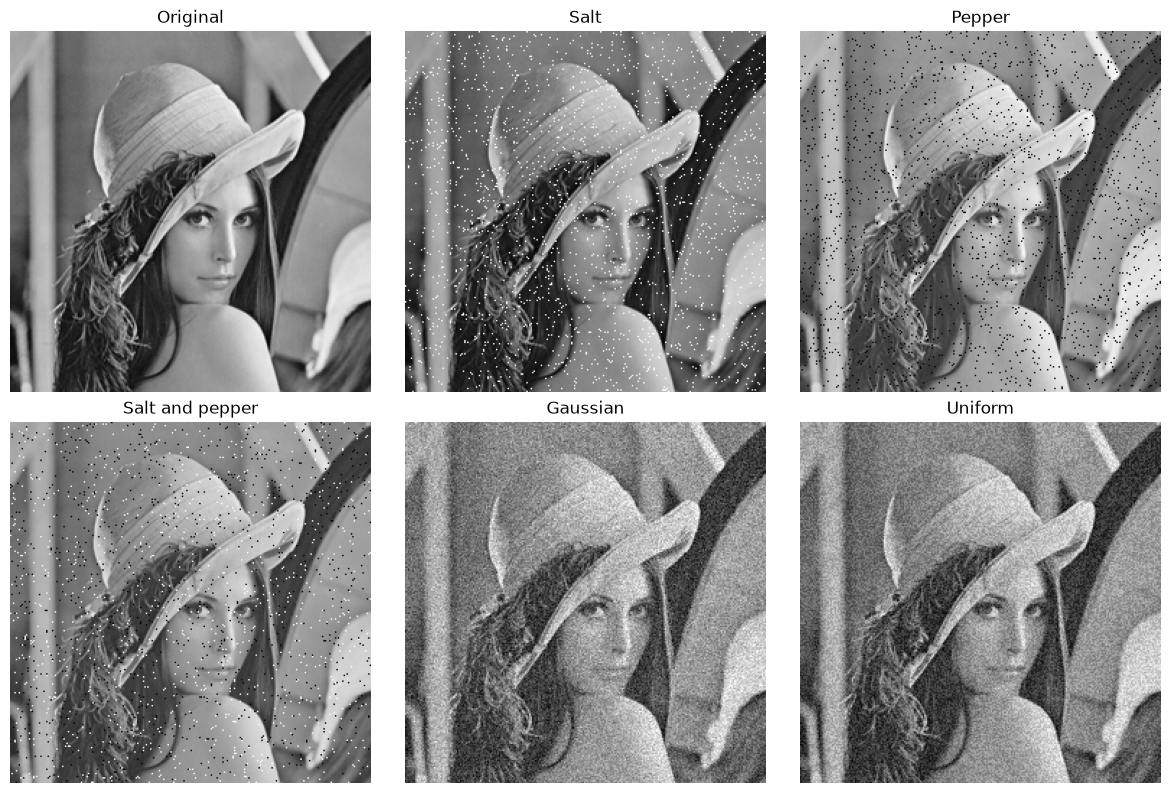

In [4]:
rng = np.random.default_rng(42)
noiseAmount = 0.03
gaussianSigma = 20
uniformLimit = 30

saltMask = rng.random(gray.shape) < noiseAmount
pepperMask = rng.random(gray.shape) < noiseAmount
saltImage = gray.copy()
pepperImage = gray.copy()
saltImage[saltMask] = 255
pepperImage[pepperMask] = 0

impulseMask = rng.random(gray.shape)
saltPepperImage = gray.copy()
saltPepperImage[impulseMask < noiseAmount / 2] = 0
saltPepperImage[impulseMask > 1 - noiseAmount / 2] = 255

gaussianNoise = rng.normal(0, gaussianSigma, gray.shape)
uniformNoise = rng.uniform(-uniformLimit, uniformLimit, gray.shape)
gaussianImage = np.clip(gray.astype(np.float32) + gaussianNoise, 0, 255).astype(np.uint8)
uniformImage = np.clip(gray.astype(np.float32) + uniformNoise, 0, 255).astype(np.uint8)

display_images({"Original": gray, "Salt": saltImage, "Pepper": pepperImage, "Salt and pepper": saltPepperImage, "Gaussian": gaussianImage, "Uniform": uniformImage}, columns=3, figsize=(12, 8))

### Kernels and settings

Choose `kernelName` and `kernelSizes` here. `kernel` uses the first size; `sizeKernels` stores every selected size. Rectangle, cross, ellipse, and line kernels come from OpenCV. NumPy creates the diagonals and the X-shaped reverse cross.

The fixed `hitmiss` pattern uses 1 for foreground, -1 for background, and 0 for ignored positions. An ellipse with equal width and height approximates a circle.

In [5]:
kernelName = "cross"
kernelSizes = [(3, 3), (5, 5), (7, 7)]
iterations = range(1, 4)
sizeKernels = {}

for kernelSize in kernelSizes:
    width, height = kernelSize

    kernels = {
        "rect": cv.getStructuringElement(cv.MORPH_RECT, kernelSize),
        "cross": cv.getStructuringElement(cv.MORPH_CROSS, kernelSize),
        "ellipse": cv.getStructuringElement(cv.MORPH_ELLIPSE, kernelSize),
        "diagonal": np.eye(height, width, dtype=np.uint8),
        "antiDiagonal": np.fliplr(np.eye(height, width, dtype=np.uint8)).copy(),
        "horizontal": cv.getStructuringElement(cv.MORPH_RECT, (width, 1)),
        "vertical": cv.getStructuringElement(cv.MORPH_RECT, (1, height)),
        "reverseCross": np.maximum(np.eye(height, width, dtype=np.uint8), np.fliplr(np.eye(height, width, dtype=np.uint8))),
        "hitmiss": np.array([[-1, -1, -1], [0, 1, 0], [1, 1, 1]], dtype=np.int8)
    }

    sizeKernels[kernelSize] = kernels[kernelName]

kernel = sizeKernels[kernelSizes[0]]

### 1. Structuring elements

Compare the shapes before using them. The reverse cross is an X, including its center. These examples use the first size in `kernelSizes`.

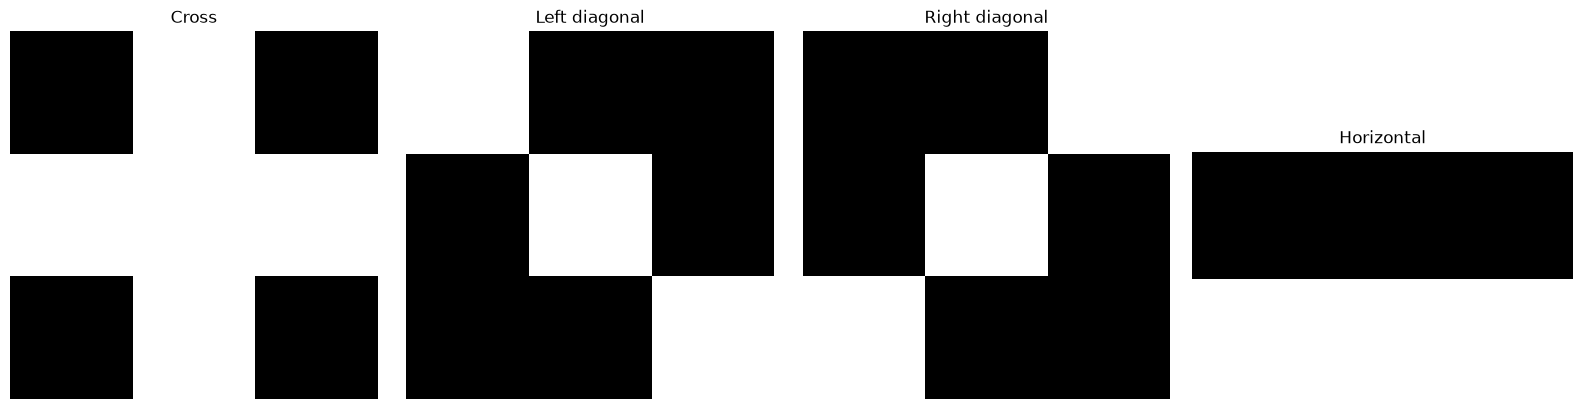

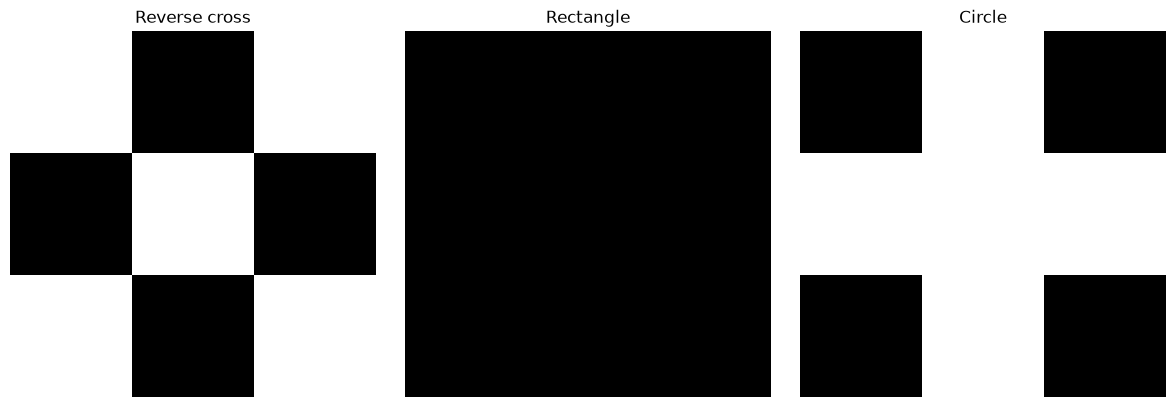

In [6]:
kernelSize = kernelSizes[0]
width, height = kernelSize

cross = cv.getStructuringElement(cv.MORPH_CROSS, kernelSize)
leftDiagonal = np.eye(height, width, dtype=np.uint8)
rightDiagonal = np.fliplr(leftDiagonal).copy()
horizontal = cv.getStructuringElement(cv.MORPH_RECT, (width, 1))
reverseCross = np.maximum(leftDiagonal, rightDiagonal)
rectangle = cv.getStructuringElement(cv.MORPH_RECT, kernelSize)
circle = cv.getStructuringElement(cv.MORPH_ELLIPSE, kernelSize)

display_images({"Cross": cross, "Left diagonal": leftDiagonal, "Right diagonal": rightDiagonal, "Horizontal": horizontal}, columns=4, figsize=(16, 4))
display_images({"Reverse cross": reverseCross, "Rectangle": rectangle, "Circle": circle}, columns=3, figsize=(12, 4))

### 2. Set operations

Use the binary image as set A and its horizontal reflection as set B. OR gives union, AND gives intersection, and XOR with 1 gives the complement of a 0/1 image. Difference keeps pixels in A that are outside B.

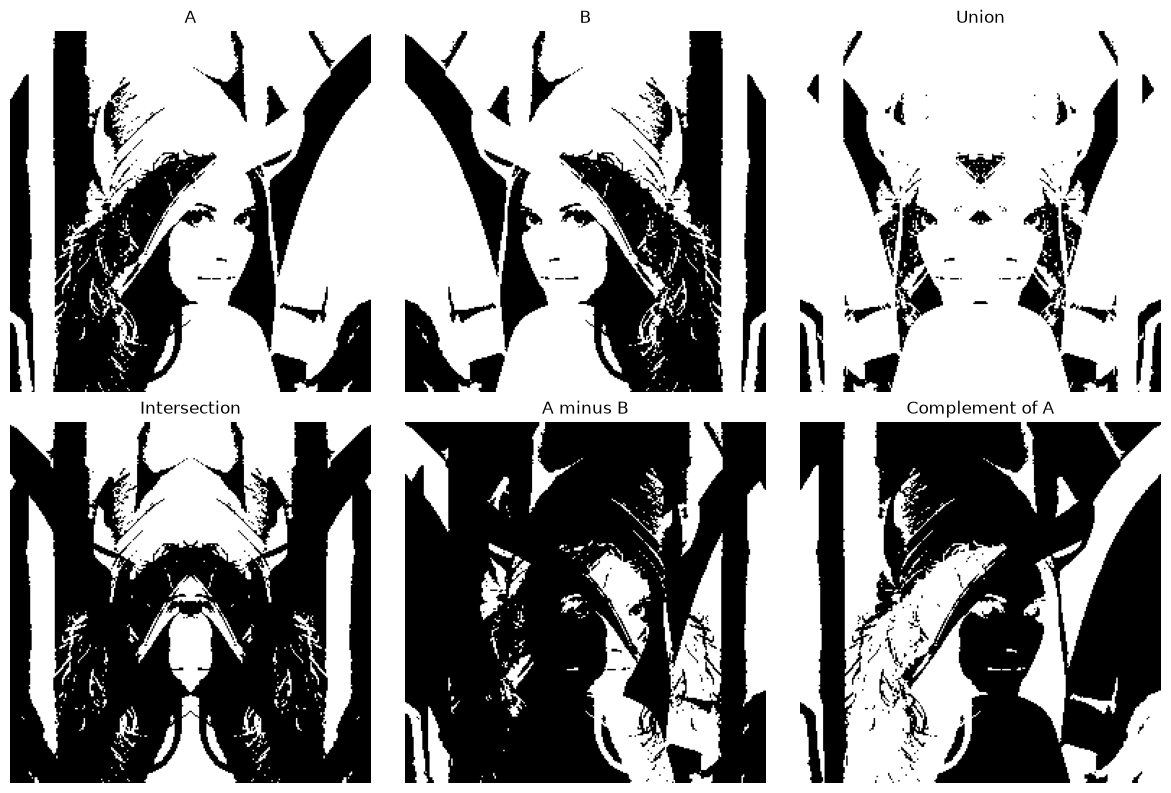

In [7]:
A = binary.copy()
B = cv.flip(binary, 1)

complement = cv.bitwise_xor(A, 1)
union = cv.bitwise_or(A, B)
intersection = cv.bitwise_and(A, B)
difference = cv.bitwise_and(A, cv.bitwise_xor(B, 1))

display_images({"A": A, "B": B, "Union": union, "Intersection": intersection, "A minus B": difference, "Complement of A": complement}, columns=3, figsize=(12, 8))

### 3. Remove random salt noise using erosion

Random locations are set to white in the grayscale image. Erosion suppresses bright impulses but darkens and shrinks bright regions. Opening restores some region size after erosion. Both can alter real image details; they do not reconstruct the image exactly.

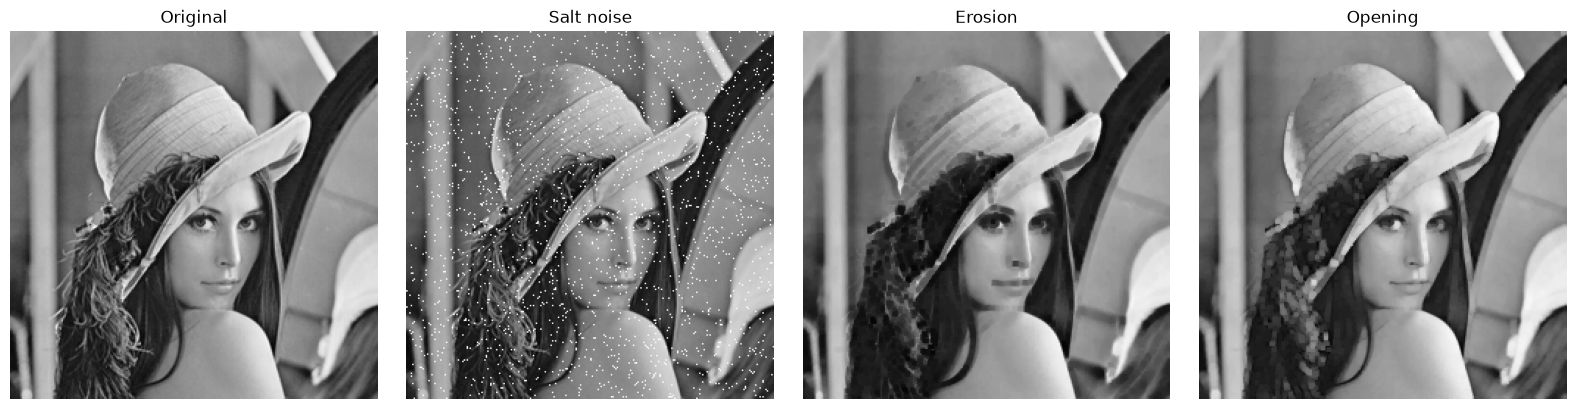

In [8]:
noiseKernel = rectangle
eroded = cv.erode(saltImage, noiseKernel)
opening = cv.morphologyEx(saltImage, cv.MORPH_OPEN, noiseKernel)

display_images({"Original": gray, "Salt noise": saltImage, "Erosion": eroded, "Opening": opening}, columns=4, figsize=(16, 4))

### 4. Remove random pepper noise using dilation

Random locations are set to black in the image. Dilation suppresses dark impulses but brightens and expands bright regions. Closing follows dilation with erosion to reduce this expansion.

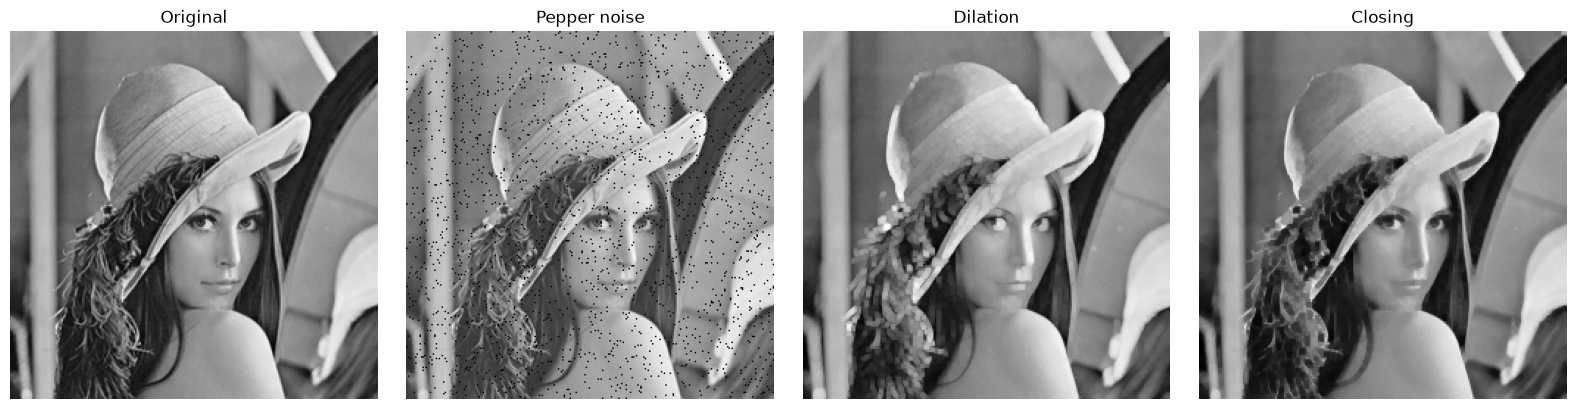

In [9]:
dilated = cv.dilate(pepperImage, noiseKernel)
closing = cv.morphologyEx(pepperImage, cv.MORPH_CLOSE, noiseKernel)

display_images({"Original": gray, "Pepper noise": pepperImage, "Dilation": dilated, "Closing": closing}, columns=4, figsize=(16, 4))

### 5. Erosion and dilation duality

For the centered, symmetric kernels used here, erosion of A equals the complement of dilation of its complement. Dilation has the corresponding relationship with erosion. Use `1 - image` because these binary images contain 0 and 1.

**Inference:** Both equality checks should print `True`.

Erosion duality: True
Dilation duality: True


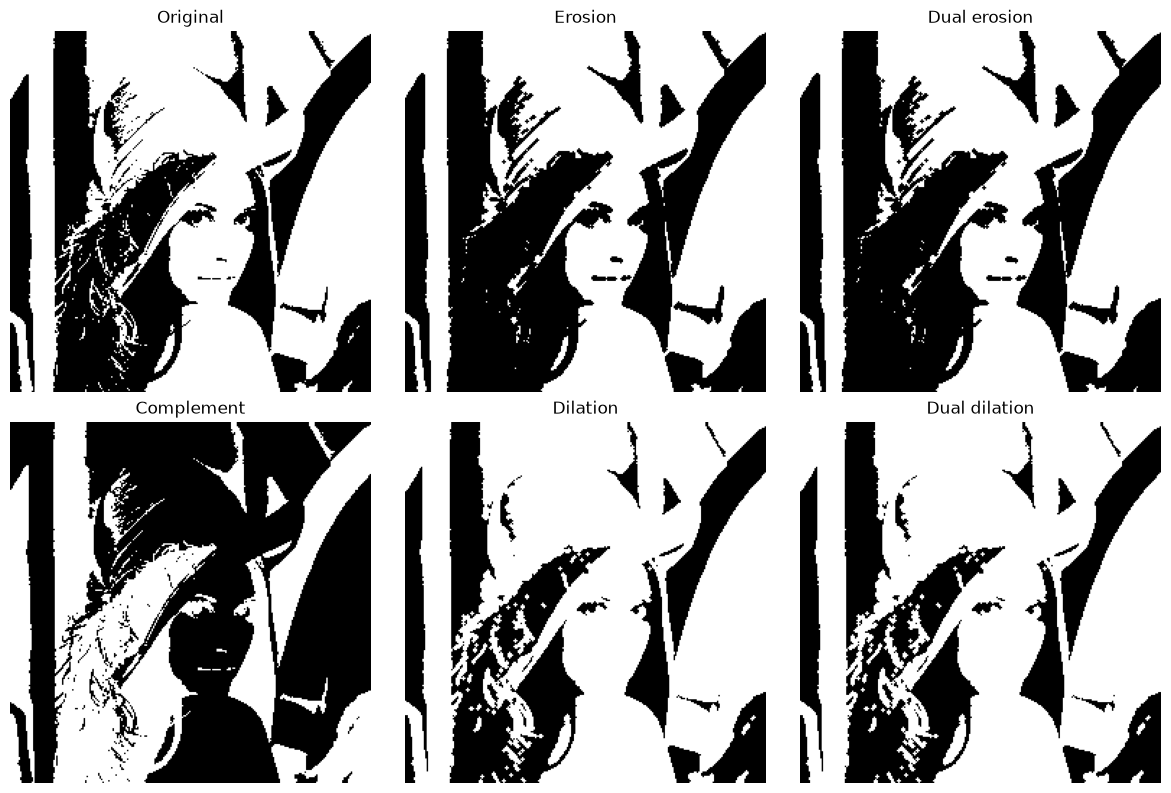

In [10]:
complement = 1 - binary

eroded = cv.erode(binary, kernel)
dualErosion = 1 - cv.dilate(complement, kernel)
dilated = cv.dilate(binary, kernel)
dualDilation = 1 - cv.erode(complement, kernel)

print("Erosion duality:", np.array_equal(eroded, dualErosion))
print("Dilation duality:", np.array_equal(dilated, dualDilation))

display_images({"Original": binary, "Erosion": eroded, "Dual erosion": dualErosion, "Complement": complement, "Dilation": dilated, "Dual dilation": dualDilation}, columns=3, figsize=(12, 8))

### 6. Boundary extraction

Subtract erosion from the original to get the inner boundary. Subtract the original from dilation to get the outer boundary. Dilation minus erosion gives the morphological gradient.

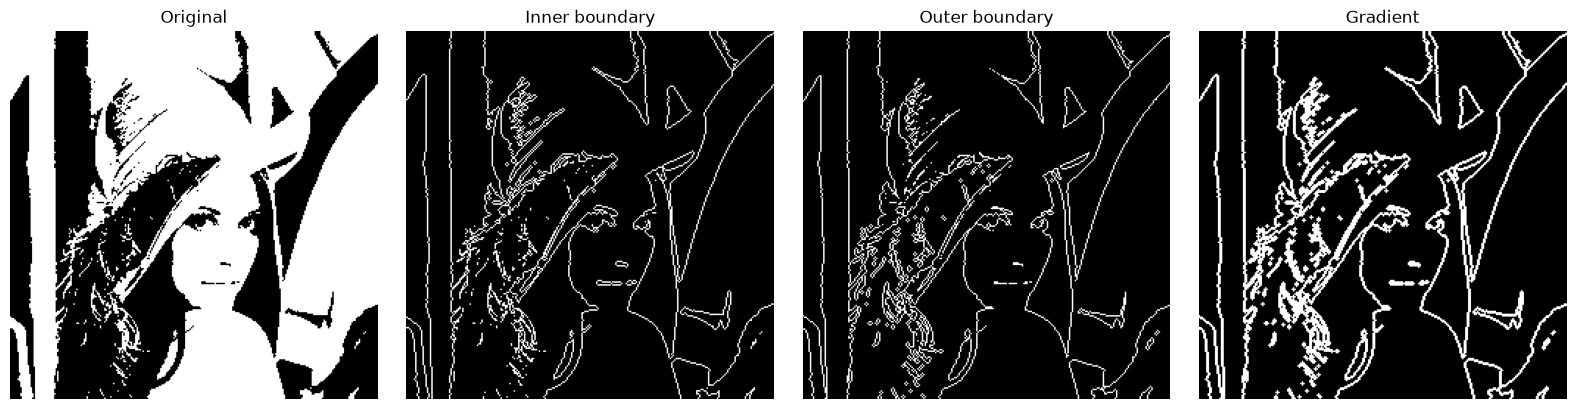

In [11]:
eroded = cv.erode(binary, kernel)
dilated = cv.dilate(binary, kernel)

innerBoundary = cv.subtract(binary, eroded)
outerBoundary = cv.subtract(dilated, binary)
gradient = cv.subtract(dilated, eroded)

display_images({"Original": binary, "Inner boundary": innerBoundary, "Outer boundary": outerBoundary, "Gradient": gradient}, columns=4, figsize=(16, 4))

### 7. Opening and closing duality

Use the grayscale image with random salt-and-pepper noise. Its complement is `255 - image`. For centered, symmetric kernels, opening equals complemented closing of the complement, and closing equals complemented opening of the complement.

Opening duality: True
Closing duality: True


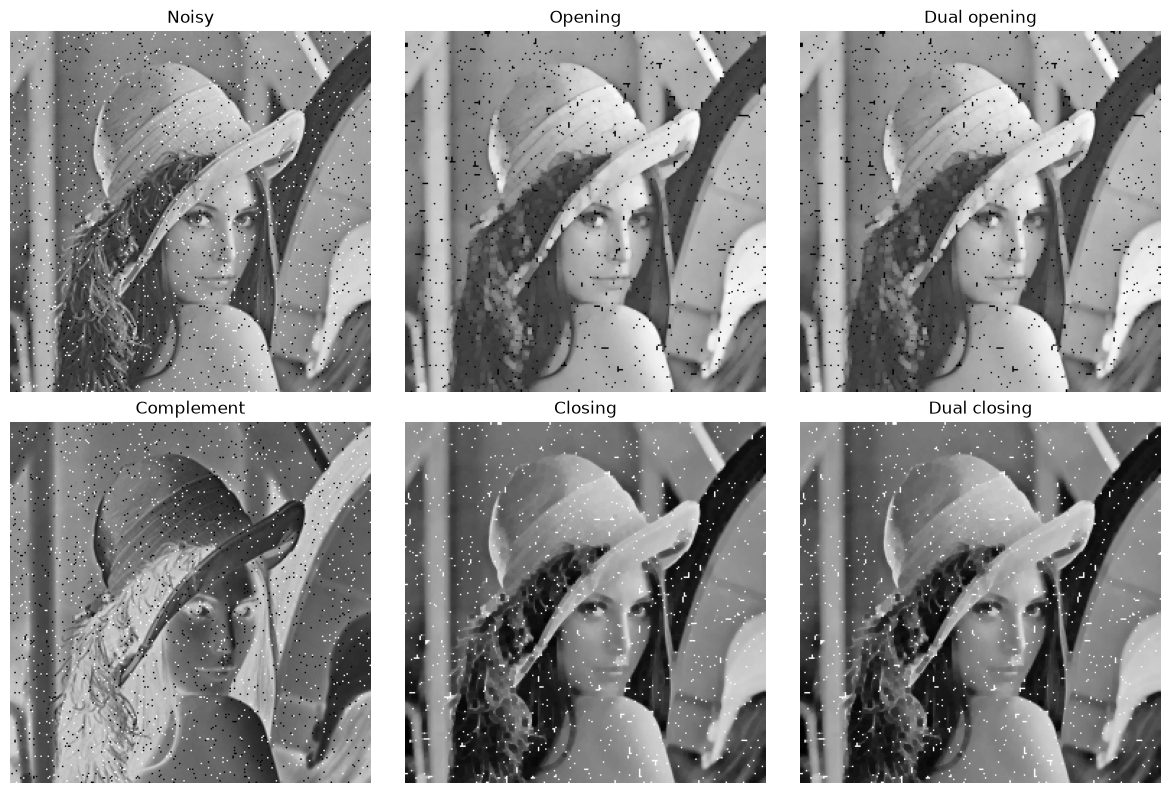

In [12]:
noisy = saltPepperImage
complement = 255 - noisy

opening = cv.morphologyEx(noisy, cv.MORPH_OPEN, noiseKernel)
closing = cv.morphologyEx(noisy, cv.MORPH_CLOSE, noiseKernel)
dualOpening = 255 - cv.morphologyEx(complement, cv.MORPH_CLOSE, noiseKernel)
dualClosing = 255 - cv.morphologyEx(complement, cv.MORPH_OPEN, noiseKernel)

print("Opening duality:", np.array_equal(opening, dualOpening))
print("Closing duality:", np.array_equal(closing, dualClosing))

display_images({"Noisy": noisy, "Opening": opening, "Dual opening": dualOpening, "Complement": complement, "Closing": closing, "Dual closing": dualClosing}, columns=3, figsize=(12, 8))

### 8. Hit-or-miss pattern detection

The signed kernel detects a top horizontal edge: background above, foreground at the center, and three foreground pixels below. The output marks matching center pixels.

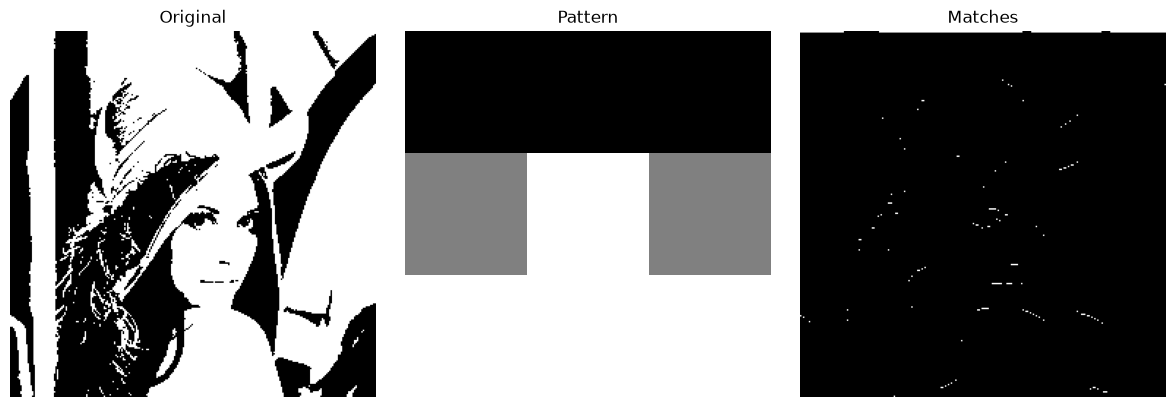

In [13]:
hitmissKernel = kernels["hitmiss"]
hitmiss = cv.morphologyEx(binary, cv.MORPH_HITMISS, hitmissKernel)

display_images({"Original": binary, "Pattern": hitmissKernel, "Matches": hitmiss}, columns=3, figsize=(12, 4))

### 9. Top-hat: extract small bright details

Top-hat is the image minus its opening. On the noisy image it highlights bright impulses and fine bright image details. It cannot distinguish noise from genuine features by itself.

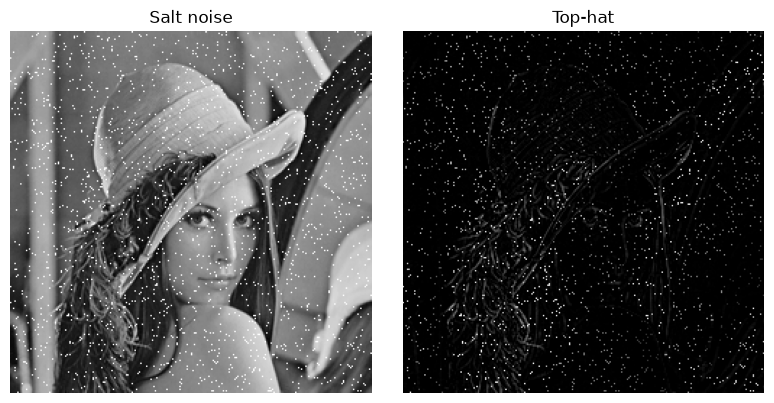

In [14]:
topHat = cv.morphologyEx(saltImage, cv.MORPH_TOPHAT, noiseKernel)

display_images({"Salt noise": saltImage, "Top-hat": topHat}, columns=2, figsize=(8, 4))

### 10. Black-hat: extract small dark details

Black-hat is closing minus the image. On the noisy image it highlights dark impulses and fine dark image details.

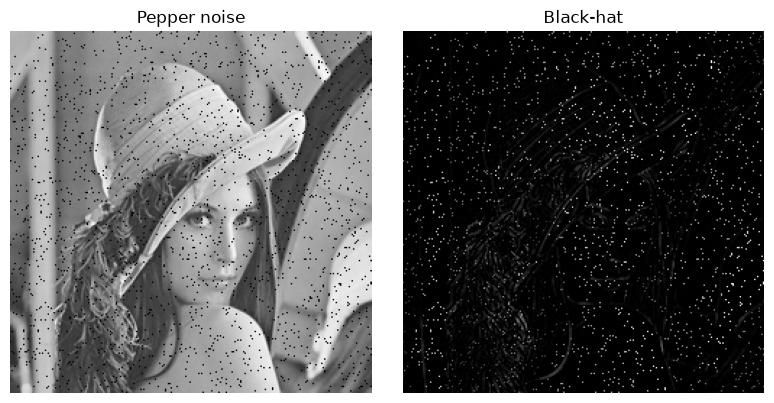

In [15]:
blackHat = cv.morphologyEx(pepperImage, cv.MORPH_BLACKHAT, noiseKernel)

display_images({"Pepper noise": pepperImage, "Black-hat": blackHat}, columns=2, figsize=(8, 4))

### 11. Fill holes in a binary image

Pad the binary mask with a black border. A seed at the corner grows through connected background pixels until it stops changing. Inverting this exterior background fills enclosed holes. Padding ensures that the seed starts outside the objects.

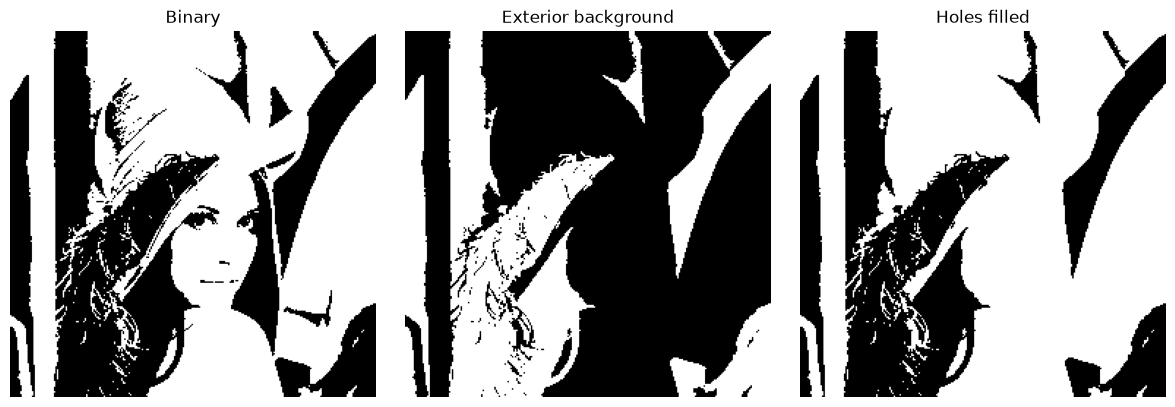

In [16]:
region = cv.copyMakeBorder(binary, 1, 1, 1, 1, cv.BORDER_CONSTANT, value=0)
regionComplement = 1 - region
seed = np.zeros_like(region)
seed[0, 0] = 1
filled = seed.copy()

while True:
    previous = filled.copy()
    filled = cv.dilate(filled, cross)
    filled = cv.bitwise_and(filled, regionComplement)

    if np.array_equal(filled, previous):
        break

exterior = filled[1:-1, 1:-1]
regionFilled = 1 - exterior

display_images({"Binary": binary, "Exterior background": exterior, "Holes filled": regionFilled}, columns=3, figsize=(12, 4))

### 12. Convex hulls of binary regions

Find each external contour in the thresholded image and fill its smallest enclosing convex shape. Hulls fill concavities and may cover background that was outside the original regions.

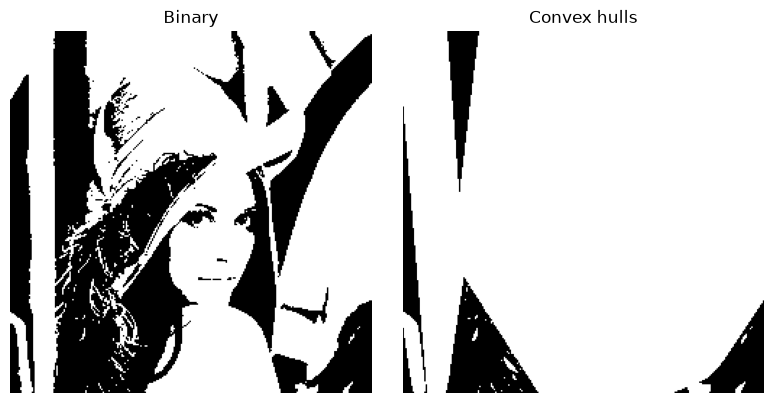

In [17]:
contours, _ = cv.findContours(binary, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
convexHullImage = np.zeros_like(binary)

for contour in contours:
    hull = cv.convexHull(contour)
    cv.drawContours(convexHullImage, [hull], -1, 1, cv.FILLED)

display_images({"Binary": binary, "Convex hulls": convexHullImage}, columns=2, figsize=(8, 4))

### 13. Thinning a binary image

Thinning reduces the foreground of the thresholded image toward a one-pixel-wide skeleton. OpenCV requires foreground values of 255 and `ximgproc.thinning` from `opencv-contrib-python`.

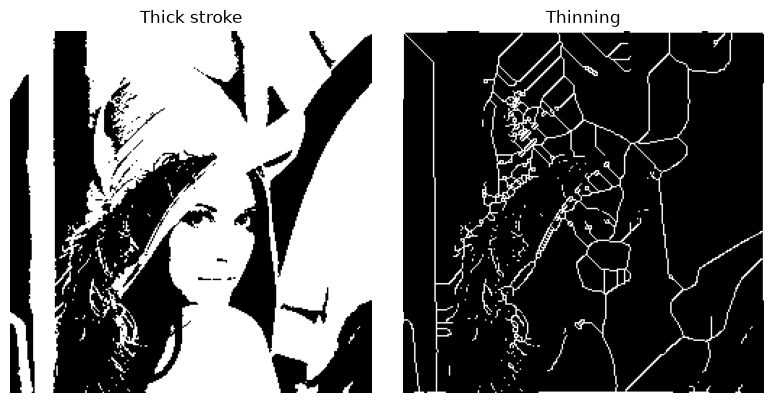

In [18]:
if hasattr(cv, "ximgproc") and hasattr(cv.ximgproc, "thinning"):
    thinning = cv.ximgproc.thinning(binary * 255)
    display_images({"Thick stroke": binary, "Thinning": thinning}, columns=2, figsize=(8, 4))
else:
    print("Thinning requires opencv-contrib-python.")

### 14. Thicken boundaries using dilation

Extract thin boundaries from the binary image, then compare repeated dilation. This increases edge thickness. It is a simple thickening approximation; formal morphological thickening uses hit-or-miss patterns.

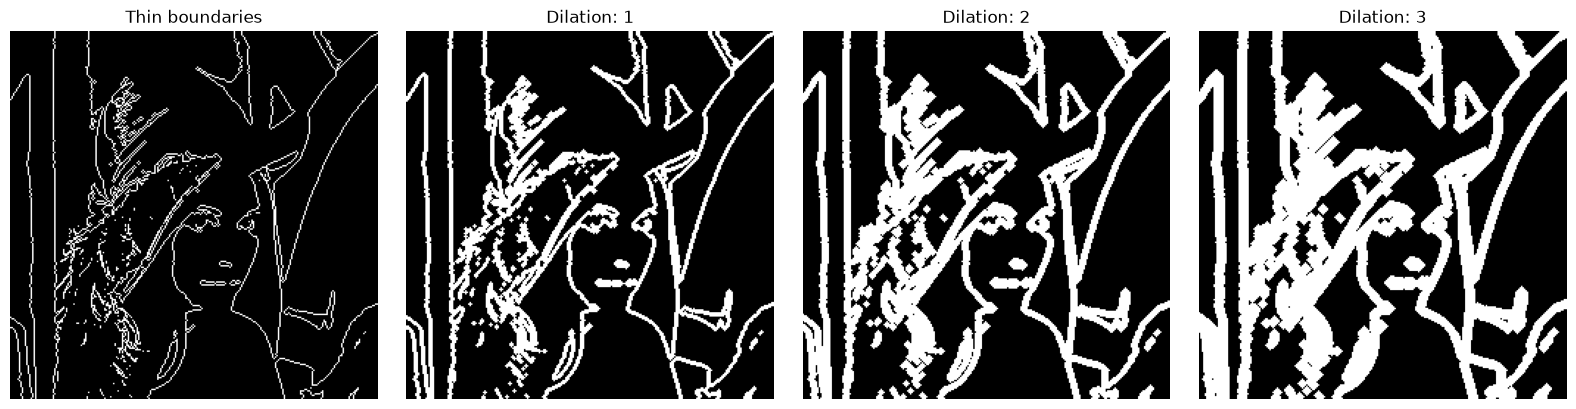

In [19]:
eroded = cv.erode(binary, kernel)
thinLines = cv.subtract(binary, eroded)
images = {"Thin boundaries": thinLines}

for iteration in iterations:
    thickening = cv.dilate(thinLines, kernel, iterations=iteration)
    images[f"Dilation: {iteration}"] = thickening

display_images(images, columns=4, figsize=(16, 4))

### 15. Morphology on a grayscale image

Erosion takes local minima, while dilation takes local maxima. Opening suppresses small bright details, and closing fills small dark details. This comparison uses the clean image to show how each operation changes real image features.

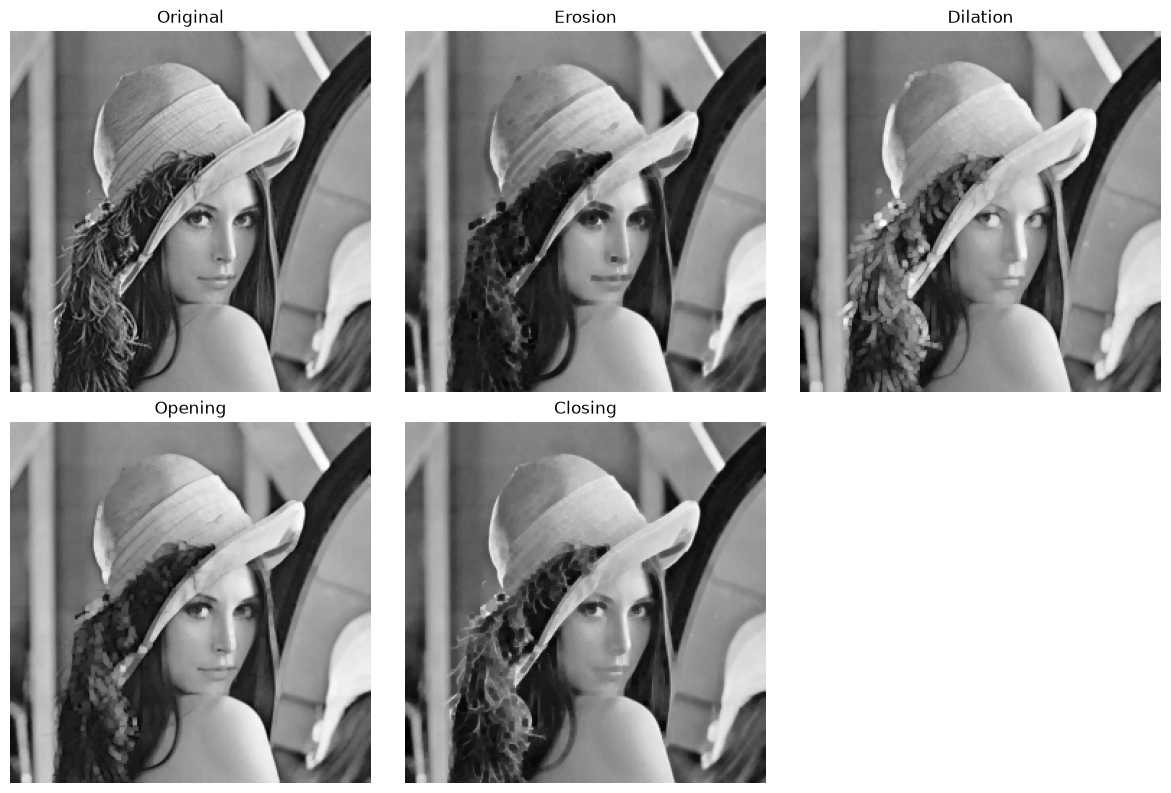

In [20]:
grayErosion = cv.erode(gray, noiseKernel)
grayDilation = cv.dilate(gray, noiseKernel)
grayOpening = cv.morphologyEx(gray, cv.MORPH_OPEN, noiseKernel)
grayClosing = cv.morphologyEx(gray, cv.MORPH_CLOSE, noiseKernel)

display_images({"Original": gray, "Erosion": grayErosion, "Dilation": grayDilation, "Opening": grayOpening, "Closing": grayClosing}, columns=3, figsize=(12, 8))

### 16. Watershed segmentation

Opening cleans the binary image. The distance transform selects interior foreground seeds, and connected components label them. Watershed grows these labels through unknown pixels and marks boundaries in red. The resulting regions depend on the foreground threshold and the selected seeds.

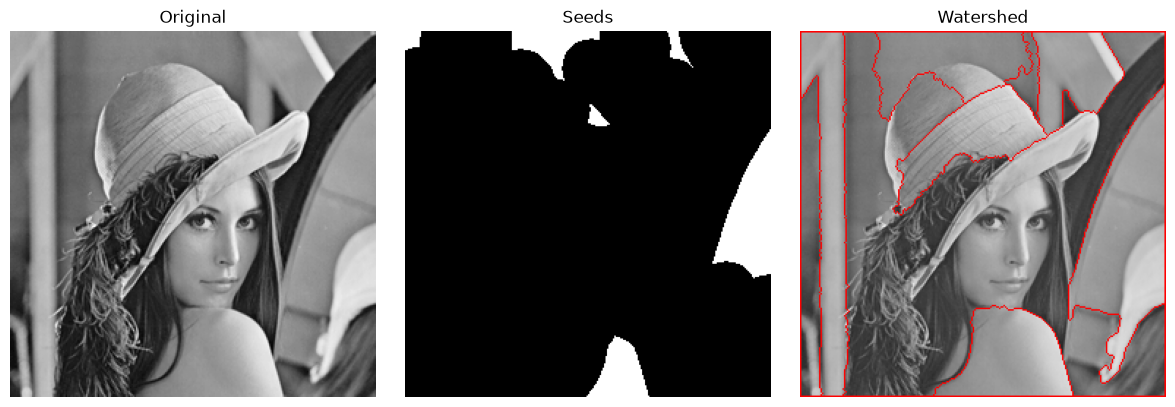

In [21]:
watershedBinary = cv.morphologyEx(binary * 255, cv.MORPH_OPEN, kernel)
sureBackground = cv.dilate(watershedBinary, kernel, iterations=3)
distance = cv.distanceTransform(watershedBinary, cv.DIST_L2, 5)
sureForeground = np.uint8(distance > 0.4 * distance.max()) * 255
unknown = cv.subtract(sureBackground, sureForeground)

_, markers = cv.connectedComponents(sureForeground)
markers += 1
markers[unknown == 255] = 0

watershedImage = cv.cvtColor(gray, cv.COLOR_GRAY2RGB)
markers = cv.watershed(watershedImage, markers)
watershedImage[markers == -1] = [255, 0, 0]

display_images({"Original": gray, "Seeds": sureForeground, "Watershed": watershedImage}, columns=3, figsize=(12, 4))

### 17. Compare filtering on random noise

For each the noisy image image, compare opening, closing, and a smoothing filter. Gaussian and uniform noise affect many pixel intensities, so smoothing is more suitable than treating them as isolated impulses. Median filtering is included for salt-and-pepper noise. Morphology changes local shapes and brightness; it is not a general replacement for these denoising filters.

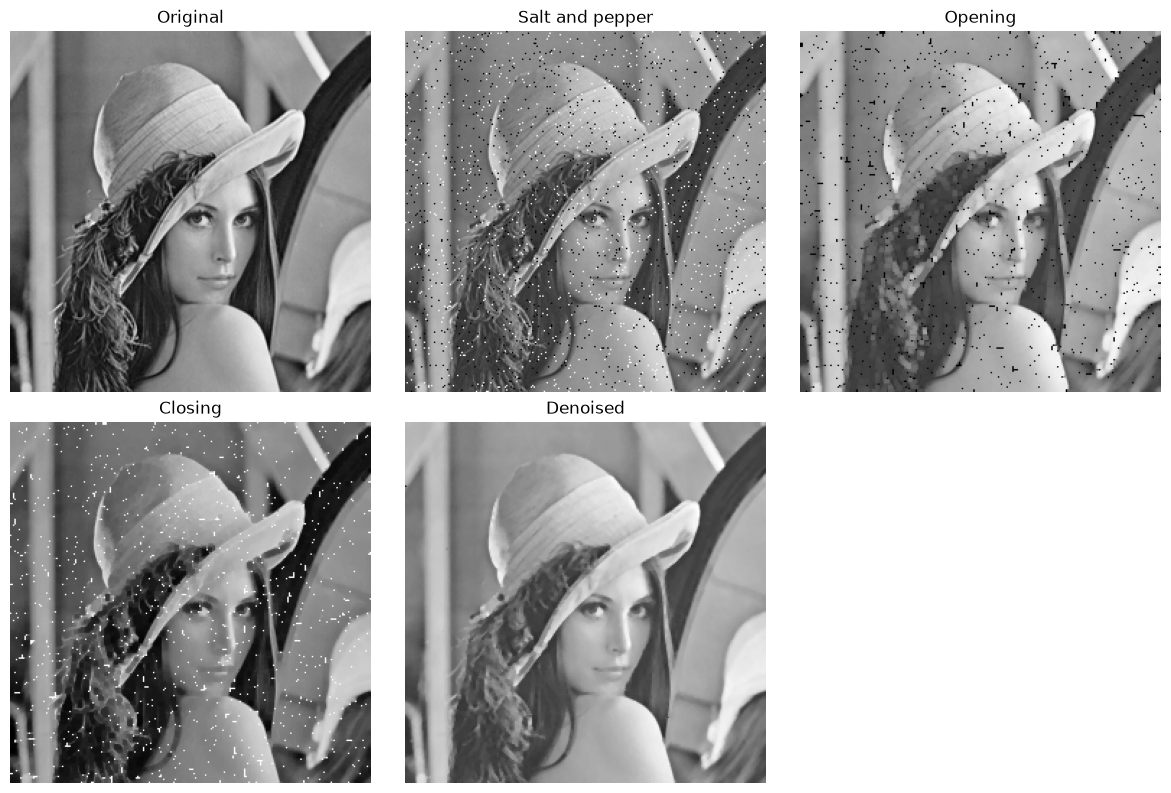

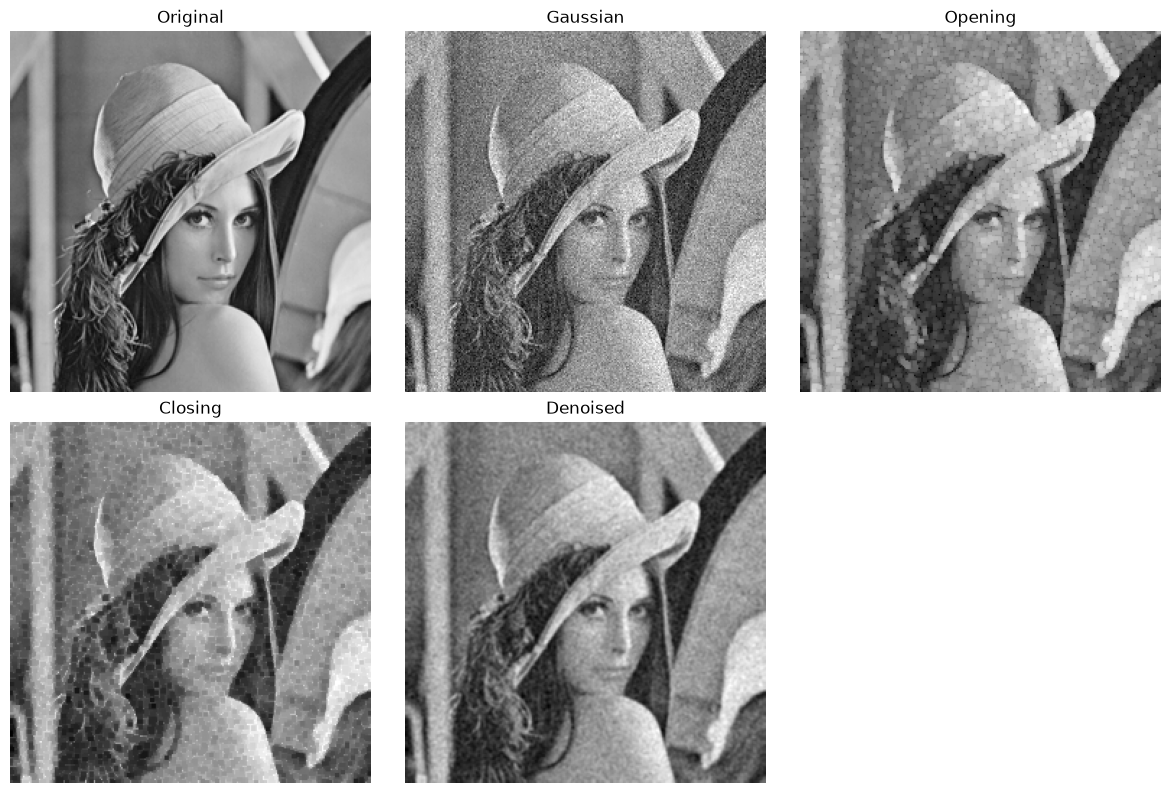

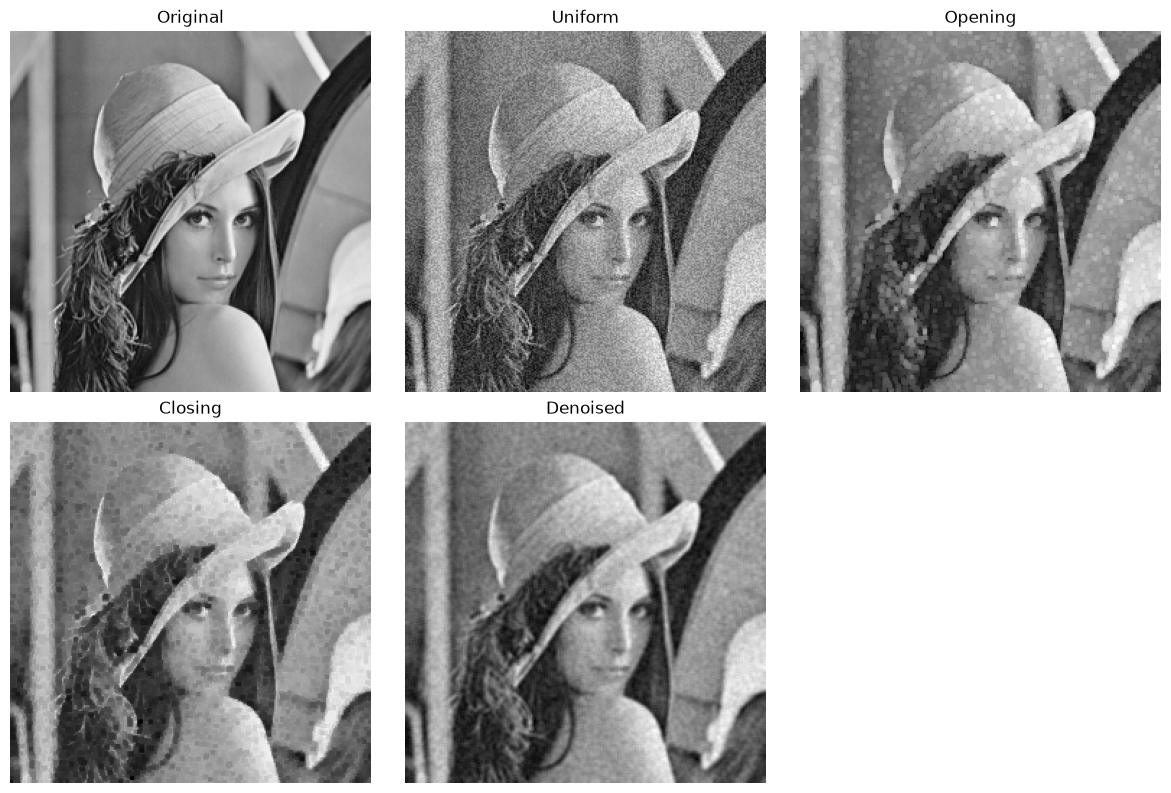

In [22]:
filteredImages = {
    "Salt and pepper": (saltPepperImage, cv.medianBlur(saltPepperImage, 3)),
    "Gaussian": (gaussianImage, cv.GaussianBlur(gaussianImage, (3, 3), 0)),
    "Uniform": (uniformImage, cv.blur(uniformImage, (3, 3)))
}

for name, (noisyImage, smoothed) in filteredImages.items():
    opening = cv.morphologyEx(noisyImage, cv.MORPH_OPEN, noiseKernel)
    closing = cv.morphologyEx(noisyImage, cv.MORPH_CLOSE, noiseKernel)
    display_images({"Original": gray, name: noisyImage, "Opening": opening, "Closing": closing, "Denoised": smoothed}, columns=3, figsize=(12, 8))